In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

# Percentiles
`percentile(p, values_array)`
- Returns the smallest value in `values_array` that is at least as large as `p`% of the elements in the array
- `p` is always between 0 and  100

In [2]:
# Manually compute the 55th percentile.
x = make_array(43, 20, 51, 7, 28, 34)

In [28]:
# Step 1. Sort the data
x.sort()
x

array([ 7, 20, 28, 34, 43, 51])

In [34]:
# Step 2. Figure out where 55th percentile would be.
# The Xth percentile is first value on the sorted list that is at least as large as X% of the elements 
k = (55/100) * len(x)
k

3.3000000000000003

The 55th Percentile is 34

In [32]:
# OR: 1 Line of Code using percentile()
percentile(55, x)

34

### Practice Questions:

In [6]:
s= [1, 7, 3, 9, 5]

In [37]:
#1 
answer1 = 1
truth1 = percentile(20, s)
answer1 == truth1

True

In [38]:
#2 
answer2 = False
truth2 = percentile(10, s) == 0
answer2 == truth2

True

In [39]:
#3 
answer3 = True
truth3 = percentile(39, s) == percentile(40, s)
answer3 == truth3

True

In [40]:
#4
answer4 = False
truth4 = percentile(40, s) == percentile(41, s)
answer4 == truth4

True

# Estimation

In [12]:
sf = Table.read_table('san_francisco_2015.csv')
sf.show(5)

Year Type,Year,Organization Group Code,Organization Group,Department Code,Department,Union Code,Union,Job Family Code,Job Family,Job Code,Job,Employee Identifier,Salaries,Overtime,Other Salaries,Total Salary,Retirement,Health/Dental,Other Benefits,Total Benefits,Total Compensation
Calendar,2015,2,"Public Works, Transportation & Commerce",WTR,PUC Water Department,21,"Prof & Tech Engineers - Miscellaneous, Local 21",2400,"Lab, Pharmacy & Med Techs",2481,Water Qualitytech I/II,21538,82146,0,0,82146,16942.2,12340.9,6337.73,35620.8,117767
Calendar,2015,2,"Public Works, Transportation & Commerce",DPW,General Services Agency - Public Works,12,"Carpet, Linoleum and Soft Tile Workers, Local 12",7300,Journeyman Trade,7393,Soft Floor Coverer,5459,32165.8,973.19,848.96,33987.9,0,4587.51,2634.42,7221.93,41209.8
Calendar,2015,4,Community Health,DPH,Public Health,790,"SEIU - Miscellaneous, Local 1021",1600,"Payroll, Billing & Accounting",1636,Health Care Billing Clerk 2,41541,71311,5757.98,0,77069,14697.6,12424.5,6370.06,33492.2,110561
Calendar,2015,4,Community Health,DPH,Public Health,351,Municipal Executive Association - Miscellaneous,0900,Management,2620,Food Service Mgr Administrator,26718,28430.2,0,763.07,29193.3,0,4223.14,5208.51,9431.65,38625
Calendar,2015,2,"Public Works, Transportation & Commerce",MTA,Municipal Transportation Agency,790,"SEIU - Miscellaneous, Local 1021",8200,Protection & Apprehension,8201,School Crossing Guard,45810,7948.75,0,0,7948.75,0,2873.17,616.24,3489.41,11438.2


In [35]:
# We only care about salary for now
salary_sf = sf.select(3, 11, 21)
salary_sf

Organization Group,Job,Total Compensation
"Public Works, Transportation & Commerce",Water Qualitytech I/II,117767
"Public Works, Transportation & Commerce",Soft Floor Coverer,41209.8
Community Health,Health Care Billing Clerk 2,110561
Community Health,Food Service Mgr Administrator,38625
"Public Works, Transportation & Commerce",School Crossing Guard,11438.2
Public Protection,Police Officer,3188.65
Community Health,Nurse Practitioner,260281
"Public Works, Transportation & Commerce",Transit Operator,111057
General Administration & Finance,Attorney (Civil/Criminal),186781
Human Welfare & Neighborhood Development,Emp & Training Spec 2,103610


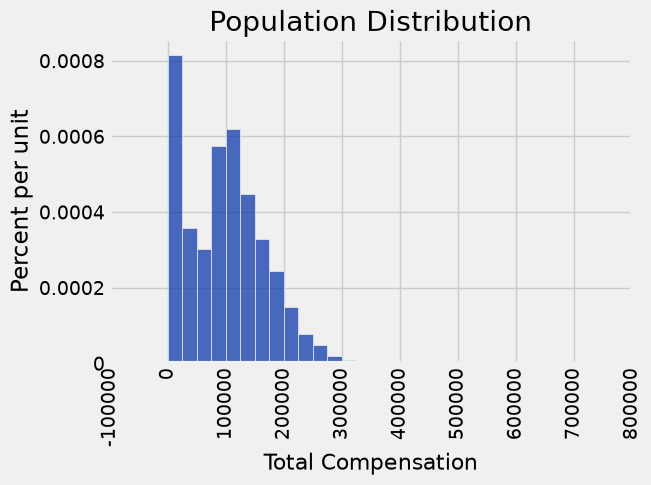

In [17]:
sf_bins = np.arange(0, 700000, 25000)
salary_sf.hist('Total Compensation', bins=sf_bins)
plots.title('Population Distribution');

**Question:** What is the typical salary? Should we compute the mean or median for this?

In [20]:
pop_median = percentile(50, sf.column('Total Compensation')) # Hint: Let's use the percentile function!
pop_median

98174.899999999994

### Estimating Salaries

In [18]:
sf.num_rows

42989

That is a lot of rows :0

How do we reduce computation?

In [19]:
our_sample = sf.sample(4000, with_replacement=False)
our_sample.show(5)

Year Type,Year,Organization Group Code,Organization Group,Department Code,Department,Union Code,Union,Job Family Code,Job Family,Job Code,Job,Employee Identifier,Salaries,Overtime,Other Salaries,Total Salary,Retirement,Health/Dental,Other Benefits,Total Benefits,Total Compensation
Calendar,2015,4,Community Health,DPH,Public Health,791,"SEIU - Staff and Per Diem Nurses, Local 1021",2300,Nursing,2320,Registered Nurse,36423,146674,935.34,42679.9,190289,39897,12223.8,3428.05,55548.8,245838
Calendar,2015,6,General Administration & Finance,ADM,General Services Agency - City Admin,21,"Prof & Tech Engineers - Miscellaneous, Local 21",1800,"Budget, Admn & Stats Analysis",1824,Pr Administrative Analyst,15432,80391.4,0,0,80391.4,5642.94,10265.1,6406.25,22314.3,102706
Calendar,2015,2,"Public Works, Transportation & Commerce",MTA,Municipal Transportation Agency,130,"Automotive Machinists, Local 1414",7300,Journeyman Trade,7381,Automotive Mechanic,12745,30480.5,181.52,628.8,31290.8,6535.96,4683.07,2433.61,13652.6,44943.4
Calendar,2015,2,"Public Works, Transportation & Commerce",MTA,Municipal Transportation Agency,236,"Carpenters, Local 22",7300,Journeyman Trade,7344,Carpenter,43609,37436.9,2515.83,1804.45,41757.2,0,5399.88,3374.6,8774.48,50531.7
Calendar,2015,4,Community Health,DPH,Public Health,791,"SEIU - Staff and Per Diem Nurses, Local 1021",2300,Nursing,2320,Registered Nurse,41731,68533.5,327.77,12725.4,81586.7,15081.7,7248.03,6557.02,28886.8,110473


In [23]:
estimate_median = percentile(50, our_sample.column('Total Compensation'))
estimate_median

97004.449999999997

In [21]:
pop_median

98174.899999999994

**Question:** How far off is our estimate from the true median?

In [24]:
error = abs(estimate_median - pop_median)
error

1170.4499999999971

In [36]:
pop_median, estimate_median, error

(98174.899999999994, 97004.449999999997, 1170.4499999999971)